In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

D:\Anaconda\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df = pd.read_csv("26-customer_data.csv")

In [3]:
df.head()

,Annual_Income,Spending_Score
0,-5.772478,-4.818216
1,6.768246,-5.424570
2,5.796159,-6.239967
3,7.096022,-5.272612
4,-5.725561,-9.316889


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1499 entries, 0 to 1498
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Annual_Income   1499 non-null   float64
 1   Spending_Score  1499 non-null   float64
dtypes: float64(2)
memory usage: 23.6 KB


In [5]:
df.describe()

,Annual_Income,Spending_Score
count,1499.000000,1499.000000
mean,-1.858568,-6.633932
std,6.895124,2.608376
min,-10.709274,-12.978282
25%,-7.316109,-9.264460
50%,-5.237149,-5.940883
75%,6.995162,-4.513904
max,10.056333,-1.820017


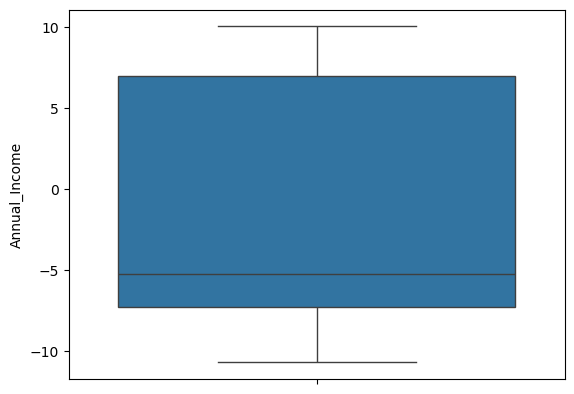

In [6]:
sns.boxplot(data=df, y="Annual_Income")
plt.show()

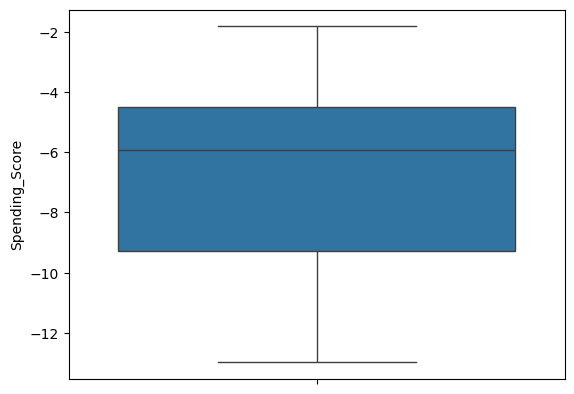

In [7]:
sns.boxplot(data=df, y="Spending_Score")
plt.show()

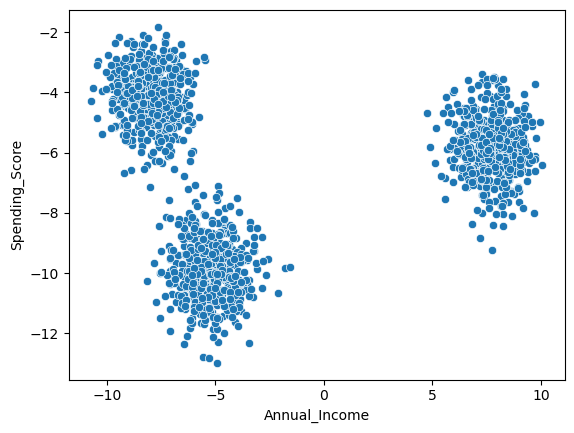

In [8]:
sns.scatterplot(data=df, x="Annual_Income", y="Spending_Score")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

In [10]:
X_train, X_test = train_test_split(df, test_size=0.2)

In [11]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [12]:
from sklearn.cluster import KMeans

In [13]:
#elbow method
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X_train_scaled)
    wcss.append(kmeans.inertia_)

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

In [14]:
wcss

[201.03993910764314,
 71.32497971807086,
 12.126474849290283,
 10.110757891589923,
 8.14086448852529,
 6.182349223395765,
 5.730563769151738,
 5.2323747599651504,
 4.6658018127010585,
 4.353829318671896]

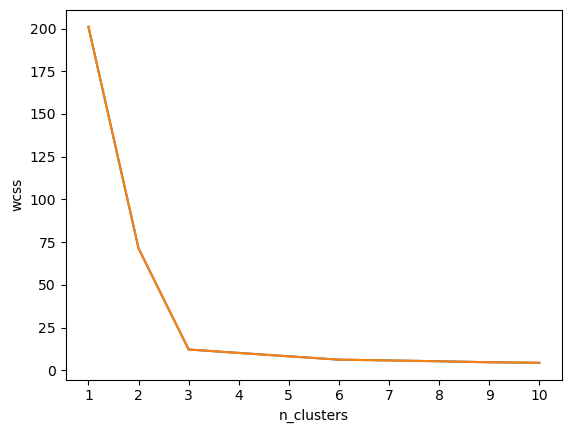

In [18]:
plt.plot(range(1,11), wcss)
plt.xticks(range(1,11))
plt.xlabel("n_clusters")
plt.ylabel("wcss")
plt.show()

In [20]:
kmeans = KMeans(n_clusters=3)
kmeans.fit(X_train_scaled)

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


KMeans(n_clusters=3)

In [21]:
y_pred = kmeans.predict(X_test_scaled)

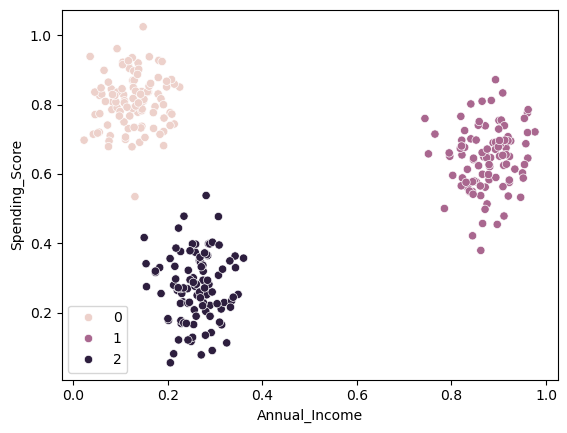

In [25]:
sns.scatterplot(data=pd.DataFrame(data=X_test_scaled, columns=X_test.columns), x="Annual_Income", y="Spending_Score", hue=y_pred)
plt.show()

In [26]:
y_pred

array([1, 1, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       2, 0, 1, 1, 2, 2, 2, 1, 2, 1, 1, 0, 0, 2, 2, 0, 0, 1, 2, 1, 2, 1,
       0, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 1, 1, 0, 2, 0, 2, 1, 1, 1, 1, 2,
       1, 0, 1, 1, 2, 0, 0, 0, 1, 1, 0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 1,
       1, 0, 2, 1, 1, 2, 1, 2, 1, 0, 0, 0, 2, 1, 1, 2, 1, 0, 2, 0, 1, 0,
       2, 2, 1, 2, 2, 0, 2, 2, 1, 0, 0, 1, 0, 1, 0, 2, 1, 0, 0, 0, 0, 2,
       1, 1, 0, 1, 2, 1, 1, 2, 1, 0, 2, 1, 0, 1, 1, 1, 2, 2, 1, 1, 0, 1,
       1, 1, 0, 1, 2, 1, 1, 0, 2, 2, 2, 0, 1, 2, 0, 1, 2, 1, 0, 0, 2, 0,
       1, 2, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 2, 2, 1, 2, 1, 0, 0,
       2, 1, 2, 2, 1, 2, 2, 0, 2, 1, 2, 2, 0, 2, 1, 2, 2, 2, 2, 2, 2, 2,
       1, 0, 2, 2, 0, 2, 2, 0, 1, 0, 0, 0, 0, 0, 1, 1, 2, 1, 2, 2, 2, 2,
       0, 2, 2, 1, 1, 0, 1, 0, 2, 2, 0, 2, 0, 1, 2, 0, 2, 2, 0, 2, 1, 1,
       2, 1, 2, 1, 0, 2, 0, 0, 2, 1, 2, 1, 1, 2, 1, 1, 2, 2, 0, 0, 2, 1,
       0, 2, 1, 0, 0, 1, 1, 1, 2, 0, 2, 1, 1, 2], d

In [27]:
!pip install kneed

  Using cached kneed-0.8.6-py3-none-any.whl.metadata (6.4 kB)
Using cached kneed-0.8.6-py3-none-any.whl (10 kB)


In [28]:
from kneed import KneeLocator

In [31]:
kl = KneeLocator(range(1,11), wcss, curve="convex", direction="decreasing")

In [32]:
kl.elbow

np.int64(3)

In [36]:
#silhouette score --> modelin başarısını da ölçmek için kullanılan bir şey.

In [38]:
from sklearn.metrics import silhouette_score

In [42]:
silhoutte_score = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++")
    kmeans.fit(X_train_scaled)
    score = silhouette_score(X_train_scaled, kmeans.labels_)
    silhoutte_score.append(score)

D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
D:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

In [43]:
silhoutte_score

[np.float64(0.6498299690965068),
 np.float64(0.786171449869987),
 np.float64(0.6558902093636806),
 np.float64(0.6241867600382118),
 np.float64(0.40592869646788016),
 np.float64(0.39374576740595174),
 np.float64(0.3586076964766557),
 np.float64(0.371337834767916),
 np.float64(0.3435519795616108)]

In [44]:
kmeans.labels_

array([0, 2, 9, ..., 3, 4, 9], shape=(1199,), dtype=int32)

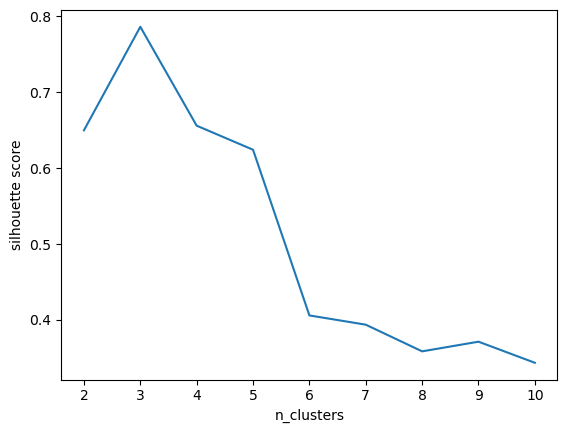

In [48]:
plt.plot(range(2,11), silhoutte_score)
plt.xticks(range(2,11))
plt.xlabel("n_clusters")
plt.ylabel("silhouette score")
plt.show()

In [50]:
# Gözetimsiz Öğrenme Ölçüm Metrikleri

In [ ]:
# Sihouette Score, Davies-Bouldin, Calinski-Horabaz